In [ ]:
# Assignment 1 — How Old Are the Patients in Our Reports?

reports with an age: 3202 | without: 3016
age_years
[0, 10)       114
[10, 20)      186
[20, 30)      193
[30, 40)      266
[40, 50)      314
[50, 60)      433
[60, 70)      708
[70, 80)      638
[80, 90)      284
[90, 100)      62
[100, 110)      4
under 18: 266 | under 2: 36 | 65 and over: 1354


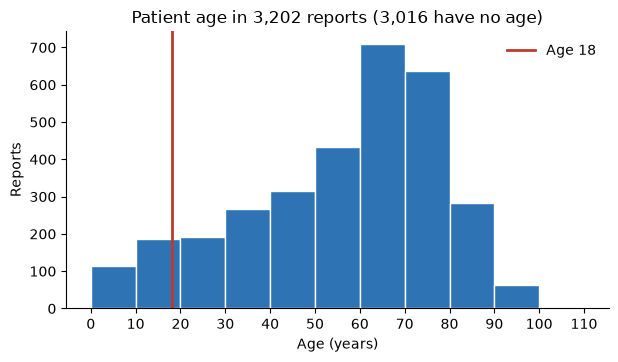

saved: a1_patient_age.png | exists: True


In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
 
def find_repo_root(marker_folder="data", start=None):
    # Search upward until we find the folder that contains data/ --
    # that only exists at the repo root, so this works from any folder.
    current = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(current, marker_folder)):
            return current
        parent = os.path.dirname(current)
        if parent == current:
            raise FileNotFoundError("No data folder found above here.")
        current = parent
 
REPO_ROOT = find_repo_root()
RAW = os.path.join(REPO_ROOT, "data", "raw")
CHART_DIR = os.path.join(REPO_ROOT, "data", "processed", "charts")
os.makedirs(CHART_DIR, exist_ok=True)
TEXT_COLUMNS = {"safety_report_id": str, "serious": str,
                "patient_age_unit": str, "country": str, "event_date": str}
EVENTS_FILE = os.path.join(RAW, "adverse_events_10k.csv")
df = pd.read_csv(EVENTS_FILE, dtype=TEXT_COLUMNS)
df["is_serious"] = df["serious"].map({"1": 1.0, "2": 0.0})
BLUE, TERRA, GRAY = "#2E74B5", "#C0392B", "#9AA5B1"
 
UNIT_TO_YEARS = {"800": 10, "801": 1, "802": 1 / 12, "803": 7 / 365.25,
                 "804": 1 / 365.25, "805": 1 / (24 * 365.25)}
age = pd.to_numeric(df["patient_age"], errors="coerce")
df["age_years"] = age * df["patient_age_unit"].map(UNIT_TO_YEARS)
ages = df["age_years"].dropna()
print("reports with an age:", len(ages), "| without:", len(df) - len(ages))
 
edges = list(range(0, 111, 10))
decades = pd.cut(ages, bins=edges, right=False).value_counts().sort_index()
print(decades.to_string())
print("under 18:", int((ages < 18).sum()),
      "| under 2:", int((ages < 2).sum()),
      "| 65 and over:", int((ages >= 65).sum()))
 
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(ages, bins=edges, color=BLUE, edgecolor="white")
ax.axvline(18, color=TERRA, linewidth=2, label="Age 18")
ax.set_title(f"Patient age in {len(ages):,} reports "
             f"({len(df) - len(ages):,} have no age)")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Reports")
ax.set_xticks(edges)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
path = os.path.join(CHART_DIR, "a1_patient_age.png")
fig.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print("saved:", os.path.basename(path), "| exists:", os.path.exists(path))


In [ ]:
# Assignment 2 — Does DUPIXENT Look Different From Everything Else?

columns add up to: [100.0, 100.0]
group                             All other drugs  DUPIXENT   gap
reaction_category                                                
Skin, allergy and injection site              5.6      34.8  29.2
Infection and breathing                       4.8       9.0   4.2
General symptoms                              5.6       5.3  -0.2
Muscles, bones and joints                     3.6       2.7  -0.8
Gut and liver                                 5.3       4.3  -1.0
Other organs and cancer                       5.4       3.7  -1.7
Product use or dosing error                  12.9      11.1  -1.8
Lack of effect                                5.3       2.7  -2.5
Brain, nerves and mood                        6.4       3.2  -3.2
Heart, blood and circulation                  5.6       1.1  -4.5
Death or hospital care                        7.3       0.5  -6.8
Unmapped                                     32.2      21.4 -10.8


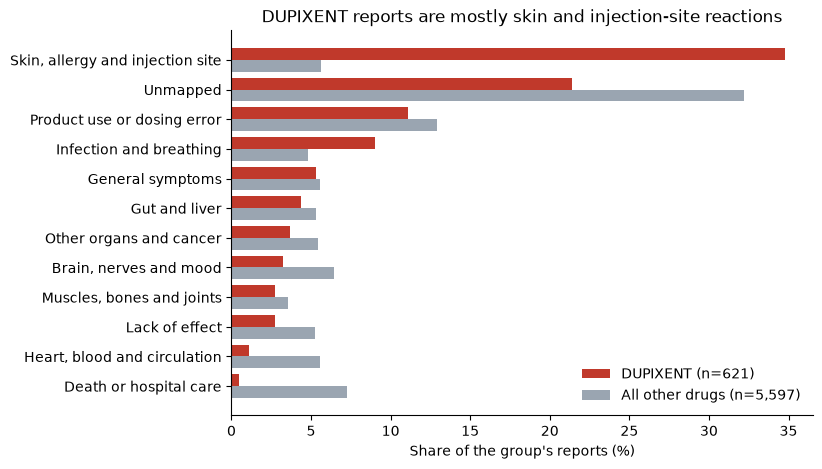

saved: a2_dupixent_profile.png | exists: True


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
 
def find_repo_root(marker_folder="data", start=None):
    # Search upward until we find the folder that contains data/ --
    # that only exists at the repo root, so this works from any folder.
    current = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(current, marker_folder)):
            return current
        parent = os.path.dirname(current)
        if parent == current:
            raise FileNotFoundError("No data folder found above here.")
        current = parent
 
REPO_ROOT = find_repo_root()
RAW = os.path.join(REPO_ROOT, "data", "raw")
CHART_DIR = os.path.join(REPO_ROOT, "data", "processed", "charts")
os.makedirs(CHART_DIR, exist_ok=True)
TEXT_COLUMNS = {"safety_report_id": str, "serious": str,
                "patient_age_unit": str, "country": str, "event_date": str}
EVENTS_FILE = os.path.join(RAW, "adverse_events_10k.csv")
df = pd.read_csv(EVENTS_FILE, dtype=TEXT_COLUMNS)
df["is_serious"] = df["serious"].map({"1": 1.0, "2": 0.0})
BLUE, TERRA, GRAY = "#2E74B5", "#C0392B", "#9AA5B1"
 
reaction_map = pd.read_csv(os.path.join(RAW, "reaction_categories.csv"))
rx = df.merge(reaction_map, on="reaction", how="left",
              validate="many_to_one")
rx["reaction_category"] = rx["reaction_category"].fillna("Unmapped")
rx["group"] = rx["drug_name"].where(rx["drug_name"] == "DUPIXENT",
                                    "All other drugs")
n = rx["group"].value_counts()
shares = pd.crosstab(rx["reaction_category"], rx["group"],
                     normalize="columns").mul(100)
print("columns add up to:", shares.sum().round(1).tolist())
shares["gap"] = shares["DUPIXENT"] - shares["All other drugs"]
shares = shares.sort_values("DUPIXENT")
print(shares.round(1).sort_values("gap", ascending=False).to_string())
 
y = range(len(shares))
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh([i + 0.2 for i in y], shares["DUPIXENT"], height=0.4,
        color=TERRA, label=f"DUPIXENT (n={n['DUPIXENT']:,})")
ax.barh([i - 0.2 for i in y], shares["All other drugs"], height=0.4,
        color=GRAY, label=f"All other drugs (n={n['All other drugs']:,})")
ax.set_yticks(list(y), shares.index)
ax.set_xlabel("Share of the group's reports (%)")
ax.set_title("DUPIXENT reports are mostly skin and injection-site reactions")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
path = os.path.join(CHART_DIR, "a2_dupixent_profile.png")
fig.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print("saved:", os.path.basename(path), "| exists:", os.path.exists(path))

In [ ]:
# Assignment 3 — Which Spikes Are Bulk Submissions?

sampled days: 104 | batch days: 16
reports in batches: 894 (14.4% of the file)
serious share, batch reports: 0.039 | all other reports: 0.543
                           drug_name   n  day_total
day                                                
2025-02-01                  RYALTRIS  79         84
2026-01-08                  DUPIXENT  77         84
2026-01-06                 OHTUVAYRE  73         87
2025-09-05                  OXERVATE  70         70
2024-11-04  POLYETHYLENE GLYCOL 3350  68         75


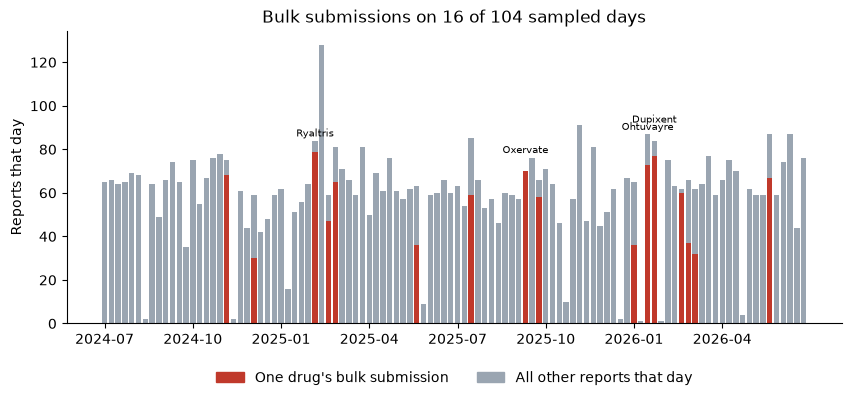

saved: a3_bulk_submissions.png | exists: True
open figures: 0


In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
 
def find_repo_root(marker_folder="data", start=None):
    # Search upward until we find the folder that contains data/ --
    # that only exists at the repo root, so this works from any folder.
    current = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(current, marker_folder)):
            return current
        parent = os.path.dirname(current)
        if parent == current:
            raise FileNotFoundError("No data folder found above here.")
        current = parent
 
REPO_ROOT = find_repo_root()
RAW = os.path.join(REPO_ROOT, "data", "raw")
CHART_DIR = os.path.join(REPO_ROOT, "data", "processed", "charts")
os.makedirs(CHART_DIR, exist_ok=True)
TEXT_COLUMNS = {"safety_report_id": str, "serious": str,
                "patient_age_unit": str, "country": str, "event_date": str}
EVENTS_FILE = os.path.join(RAW, "adverse_events_10k.csv")
df = pd.read_csv(EVENTS_FILE, dtype=TEXT_COLUMNS)
df["is_serious"] = df["serious"].map({"1": 1.0, "2": 0.0})
BLUE, TERRA, GRAY = "#2E74B5", "#C0392B", "#9AA5B1"
 
from matplotlib.patches import Patch
 
df["day"] = pd.to_datetime(df["event_date"], format="%Y%m%d")
per_day = df.groupby("day").size()
pairs = df.groupby(["day", "drug_name"]).size().reset_index(name="n")
pairs = pairs.sort_values(["day", "n", "drug_name"],
                          ascending=[True, False, True])
top = pairs.groupby("day").head(1).set_index("day")
top["day_total"] = per_day
top["share"] = top["n"] / top["day_total"]
top["batch"] = (top["n"] >= 20) & (top["share"] >= 0.5)
print("sampled days:", len(top), "| batch days:", int(top["batch"].sum()))
 
batches = top[top["batch"]]
key = pd.MultiIndex.from_arrays([df["day"], df["drug_name"]])
in_batch = key.isin(batches.set_index("drug_name", append=True).index)
print("reports in batches:", int(in_batch.sum()),
      f"({in_batch.mean():.1%} of the file)")
share_batch = df.loc[in_batch, "is_serious"].mean()
share_rest = df.loc[~in_batch, "is_serious"].mean()
print("serious share, batch reports:", round(share_batch, 3),
      "| all other reports:", round(share_rest, 3))
print(batches.sort_values("n", ascending=False)
      .head(5)[["drug_name", "n", "day_total"]].to_string())
 
x = range(len(top))
colors = [TERRA if b else GRAY for b in top["batch"]]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(x, top["n"], color=colors, width=0.8)
ax.bar(x, top["day_total"] - top["n"], bottom=top["n"], color=GRAY,
       width=0.8)
biggest = batches.nlargest(4, "n").sort_index()
for k, (day, row) in enumerate(biggest.iterrows()):
    ax.annotate(row["drug_name"].title(),
                (top.index.get_loc(day), row["day_total"]),
                xytext=(0, 3 + 10 * (k % 2)), textcoords="offset points",
                ha="center", fontsize=7)
ticks = list(range(0, len(top), 13))
ax.set_xticks(ticks, [top.index[i].strftime("%Y-%m") for i in ticks])
ax.set_ylabel("Reports that day")
ax.set_title(f"Bulk submissions on {len(batches)} of {len(top)} "
             "sampled days")
ax.legend(handles=[Patch(color=TERRA, label="One drug's bulk submission"),
                   Patch(color=GRAY, label="All other reports that day")],
          frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12),
          ncol=2)
ax.spines[["top", "right"]].set_visible(False)
path = os.path.join(CHART_DIR, "a3_bulk_submissions.png")
fig.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print("saved:", os.path.basename(path), "| exists:", os.path.exists(path))
print("open figures:", len(plt.get_fignums()))